# Project links

**Github repository**
https://github.com/phkhle/IND320/tree/project3

**Streamlitt app**
https://ind320-h2026.streamlit.app/


In [1]:
import geopandas as gpd
import sys
from pathlib import Path
import pandas as pd

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Get the parent directory, since the notebook is located one folder below the project root
project_root = Path.cwd().parent
# Add the project root to Python's module search path
# This allows Python to find and import modules from src/
sys.path.insert(0, str(project_root))

from src.forecasting import forecast_reservoir, evaluate_multistep_forecast, forecast_reservoir_snarimax, evaluate_forecasting_models
from src.forecasting import evaluate_history_length
from src.forecasting import tune_snarimax
from src.forecasting import evaluate_time_resolution


from src.weather_download import download_region_weather_daily

from src.NVE_API import get_nve_data

import matplotlib.pyplot as plt
import plotly.graph_objects as go





# Download Euro, USD currency exchange rates

# Streamlit application 

## Structure and navigation

For Project 4, the Streamlit dashboard is reorganised according to the purpose of each page rather than only the data source.

The application is divided into three main sections:

- Explore Data: 
    - Interactive Map
    - Reservoir Statistics 
    - Electricity Transfer
    - Currency Exchange.

- Analysis: 
    - STL and Spectrogram
    - Weather Anomalies
    - Sliding Window Correlation.

- Forecasting: Reservoir Filling Forecast.

A separate Home page provides an overview of the dashboard and its data sources.

The navigation was implemented using ``st.navigation()`` and ``st.Page()``. Pages can then be grouped into logical sections.

Shared geographical selections will be stored using ``st.session_state``. Users will be able to select an area on the interactive map and reuse that selection in other analyses.



## Interactive map

### Create GeoJSON

Create geographic file for the electricity pricing areas (EL)

In [2]:
# Load electricity price areas
price_areas = gpd.read_file(
    "../data/shapefiles/Budområder.shp"
)

# Convert to WGS84 coordinates
price_areas = price_areas.to_crs(epsg=4326)

# Standardize region names
price_areas["region"] = (
    price_areas["budomr"]
    .str.replace(" ", "", regex=False)
)

# Save as GeoJSON
price_areas[["region", "geometry"]].to_file(
    "../data/price_areas.geojson",
    driver="GeoJSON"
)

print("GeoJSON for electricity price areas created successfully!")

GeoJSON for electricity price areas created successfully!


Create geographic file for the precipitation areas

In [3]:
# Load rain areas
regions = gpd.read_file("../data/shapefiles/NVE_region.shp", encoding = 'utf-8')

# Map NVE administrative regions to precipitation regions
region_mapping = {
    "RS": "Øst",
    "RØ": "Øst",
    "RV": "Vest",
    "RM": "Nord",
    "RN": "Nord"
}

# Assign precipitation region names
precipitation_regions = regions.copy()
precipitation_regions["region"] = precipitation_regions["REGION"].map(region_mapping)

# Merge polygons belonging to the same precipitation region
precipitation_regions = precipitation_regions.dissolve(
    by="region",
    as_index=False
)

# Convert precipitation regions to WGS84
weather_regions_geojson = precipitation_regions.to_crs(epsg=4326)

# Keep only region names and geometry
weather_regions_geojson = weather_regions_geojson[
    ["region", "geometry"]
]

# Export as GeoJSON
weather_regions_geojson.to_file(
    "../data/weather_regions.geojson",
    driver="GeoJSON"
)

print("Weather regions GeoJSON created successfully!")

Weather regions GeoJSON created successfully!


Create geographic file for the water areas (river basin areas - VASS). For simplicity this will be divided into three regions: 1 - Øst (East), 2 - Vest (West), 3 - Nord (North). Therefore i will reuse weather_regions.geojson for VASS

# Forecasting

## Historical evaluation of 1 week forecasting

### Online evaluation with Lag-based Linear Regression model

In [4]:
# Retrieve reservoir data from NVE API
df_nve = get_nve_data()

# Select NO3
df_region = df_nve[
    (df_nve["omrType"] == "EL") &
    (df_nve["omrnr"] == 3)
].copy()


Lag-based Linear Regression (using River library) was trained with historical data from first observation available until before the last 52 weeks. 

Evaluation: Lag-based Linear Regression predicted one week ahead in the period of the last 52 weeks.

Updating process happened under the evaluation. Lag-based Linear Regression was updated with acutal value after every prediction. This means the model would gradually get more training data through the evaluation period

In [5]:
dates = (
    pd.to_datetime(df_region["dato_Id"])
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

test_weeks = 52

print("========== TRAINING ==========")
print("Start:", dates.iloc[0].date())
print("End:  ", dates.iloc[-(test_weeks + 1)].date())
print("Weeks:", len(dates) - test_weeks)

print("\n========== EVALUATION ==========")
print("Start:", dates.iloc[-test_weeks].date())
print("End:  ", dates.iloc[-1].date())
print("Weeks:", test_weeks)

========== TRAINING ==========
Start: 1995-01-08
End:   2025-11-16
Weeks: 1611

========== EVALUATION ==========
Start: 2025-11-23
End:   2026-11-15
Weeks: 52


Train River and evaluate one week ahead, then compare with the baseline model



In [6]:
results = forecast_reservoir(
    df=df_region,
    n_lags=4,
    test_weeks=52
)

results.head()

,date,actual,predicted
0,2025-11-23,0.851878,0.866210
1,2025-11-30,0.824069,0.842509
2,2025-12-07,0.795395,0.804163
3,2025-12-14,0.774006,0.767300
4,2025-12-21,0.766409,0.748065


In [7]:


mae = mean_absolute_error(
    results["actual"],
    results["predicted"]
)

rmse = np.sqrt(mean_squared_error(
    results["actual"],
    results["predicted"]
))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.0179
RMSE: 0.0218


### Baseline model

The baseline assumes that the fill rate next week will be equal to the most recent observed value. 

Baseline uses actual observations from the previous week, even when this falls within the evaluation period. This is permitted in a one-week forecast, as the value is already known at the time of prediction.

In [8]:

# Baseline: previous week's filling
df_region["baseline"] = df_region["fyllingsgrad"].shift(1)

# Use exactly the same dates as used in River model
baseline_df = results.merge(
    df_region[["dato_Id", "baseline"]],
    left_on="date",
    right_on="dato_Id",
    how="left"
)

# Remove missing values
baseline_df = baseline_df.dropna(
    subset=["actual", "predicted", "baseline"]
)

In [9]:
print("========== BASELINE ==========")
print("Training: None")
print("Evaluation start:", baseline_df["date"].min())
print("Evaluation end:  ", baseline_df["date"].max())
print("Evaluated weeks: ", len(baseline_df))

========== BASELINE ==========
Training: None
Evaluation start: 2025-11-23 00:00:00
Evaluation end:   2026-11-15 00:00:00
Evaluated weeks:  52


### Compare Lag-based Linear Regression (River) and Baseline

In [10]:
# Evaluate both models
evaluation = []

for model_name, pred_col in [
    ("River", "predicted"),
    ("Baseline", "baseline")
]:
    y_true = baseline_df["actual"]
    y_pred = baseline_df[pred_col]

    evaluation.append({
        "Model": model_name,
        "MAE (pp)": mean_absolute_error(y_true, y_pred) * 100,
        "RMSE (pp)": np.sqrt(mean_squared_error(y_true, y_pred)) * 100,
        "R²": r2_score(y_true, y_pred)
    })

evaluation_df = pd.DataFrame(evaluation).set_index("Model")

display(evaluation_df.round(4))

,MAE (pp),RMSE (pp),R²
Model,,,
River,1.7917,2.1808,0.9869
Baseline,2.4361,3.0702,0.9739


The River model outperforms the baseline on all three evaluation metrics.

However, we have so far only evaluated one week ahead, with the model being updated on an ongoing basis.

This means that these results do not tell us how well the model will predict maximum 12 weeks ahead without new observations.
Therefore I extend the model to multi-step forecasting (1–12 weeks ahead).

We can retain the existing River model as a starting point and later compare it with SNARIMAX.

## Historical evaluation of 12 weeks forecasting

the new River model was for 12-week forecasting, and regardign the new baseline: the most recent observed fill level at the start of each forecast period is used as the forecast for all 12 future weeks, then the two models were compared with each other in the validation set (all included in the `evaluate_multistep_forecast` function)

### River and Baseline

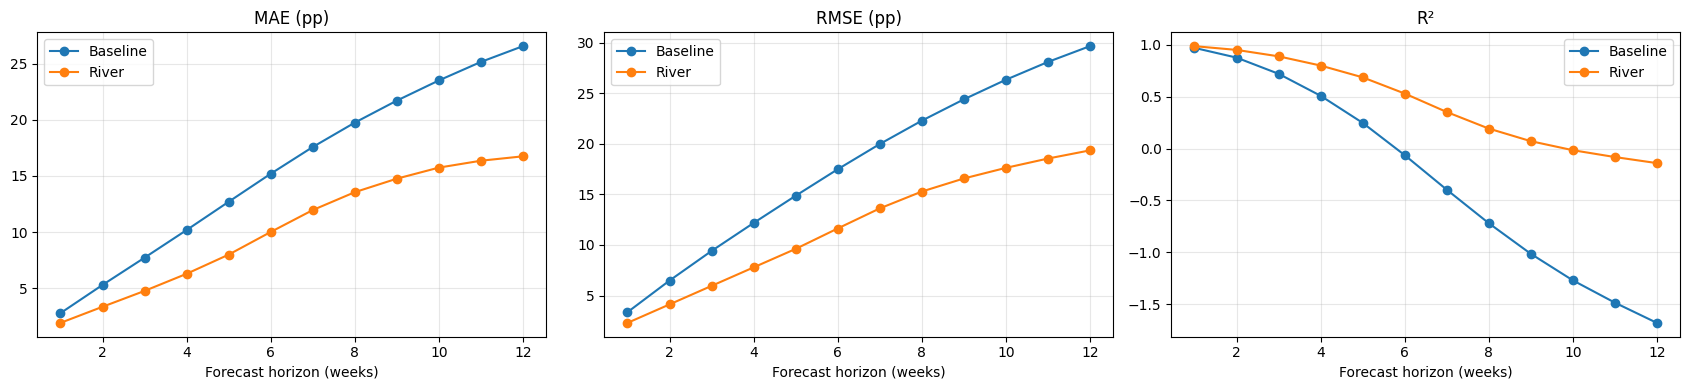

In [11]:

predictions, metrics_df = evaluate_multistep_forecast(
    df=df_region,
    n_lags=4,
    horizon=12,
    test_weeks=52
)


fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for i, metric in enumerate(["MAE (pp)", "RMSE (pp)", "R²"]):

    for model_name, group in metrics_df.groupby("Model"):

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            label=model_name
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

the River model works well in the short term, but struggles to predict reservoir levels far into the future.

The model uses only the last four weeks:
n_lags = 4. Consequently, it has limited information about annual seasonal patterns.

### SNARIMAX

Create a simple parameter search function for SNARIMAX, which evaluates different configurations using MAE, RMSE and R² over 12 forecast weeks. 

Similar to River model, The last 52 weeks of ``df_region`` are reserved for final model evaluation

*Validation period **for tuning*** is the 52 weeks right before the model evaluation period


In [12]:
# 1. Find best SNARIMAX parameters on validation data FOR TUNING

tuning_results, best_params = tune_snarimax(
    df=df_region,
    horizon=12,
    val_weeks=52,
    origin_step=4
)

display(tuning_results.round(4))

print("Best parameters:", best_params)

1/8 completed
2/8 completed
3/8 completed
4/8 completed
5/8 completed
6/8 completed
7/8 completed
8/8 completed


,p,d,q,m,sp,sd,sq,MAE (pp),RMSE (pp),R²,N predictions
0,1,1,2,52,2,0,0,5.5809,6.7140,0.8183,132
1,1,1,1,52,2,0,0,5.6825,6.8275,0.8121,132
2,2,1,2,52,2,0,0,5.6761,6.8645,0.8100,132
3,2,1,1,52,2,0,0,5.8270,7.0604,0.7990,132
4,1,1,2,52,1,0,0,5.9636,7.3068,0.7848,132
5,1,1,1,52,1,0,0,6.0961,7.4071,0.7788,132
6,2,1,2,52,1,0,0,6.1407,7.4882,0.7739,132
7,2,1,1,52,1,0,0,6.2166,7.5948,0.7674,132


Best parameters: {'p': 1, 'd': 1, 'q': 2, 'm': 52, 'sp': 2, 'sd': 0, 'sq': 0}


In [13]:
# 2. Compare all three models on validation data for MODELS (the last 52 weeks of df_region)

predictions_test, metrics_test = evaluate_forecasting_models(
    df=df_region,
    horizon=12,
    test_weeks=52,
    n_lags=4,
    snarimax_params=best_params
)


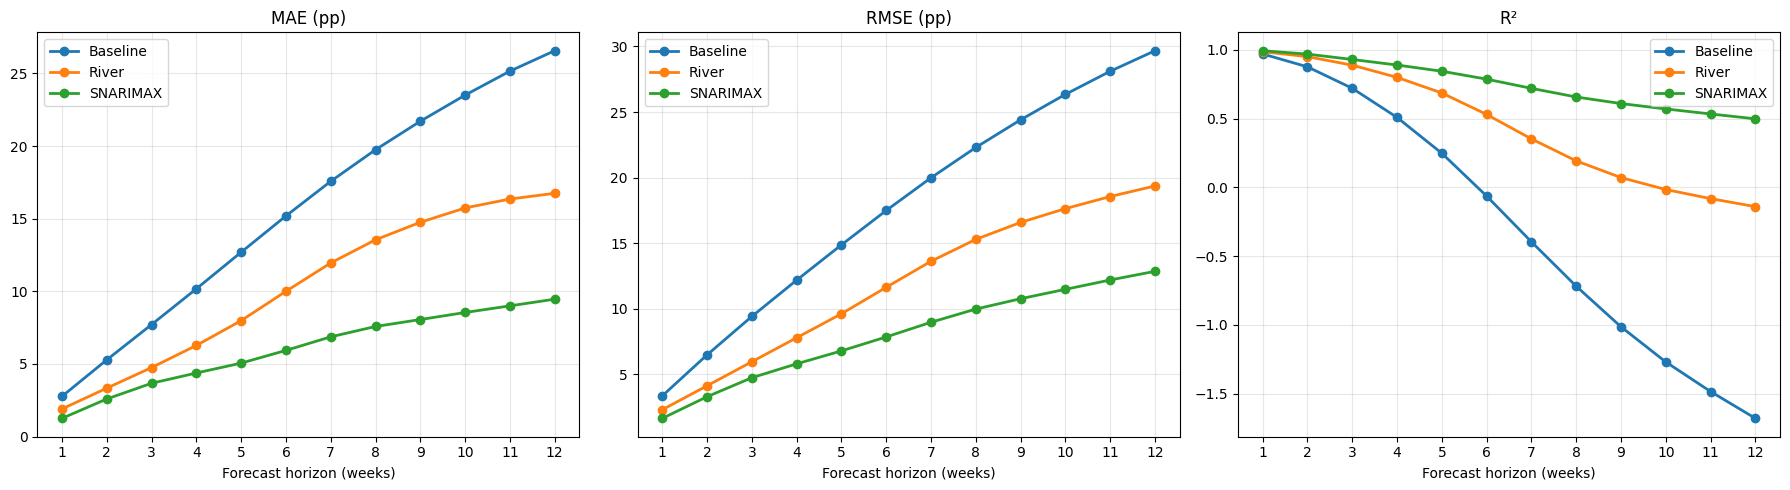

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE (pp)", "RMSE (pp)", "R²"]

for i, metric in enumerate(metrics):

    for model_name, group in metrics_test.groupby("Model"):

        group = group.sort_values("Horizon")

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            linewidth=2,
            label=model_name
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].set_xticks(range(1, 13))
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

The models are retrained at the start of each forecast period using the same available historical data, whereas the baseline requires no training. Here we see that, even though the models tend to degrade progressively after week 6, SNARIMAX remains the most stable model, maintaining positive $R^2$ values above 0.5 throughout

## Customise training history

investigate which history length works best. We can compare 5, 10 and 20 years, as well as the entire historical data set, over the same evaluation period, using the same SNARIMAX parameters and the same forecast horizon.

Note: We continue to use the last 52 weeks as the validation set for model selection. We now also use this period to determine the historical data length. It is therefore not an independent test set.

In [15]:

predictions_history, metrics_history, runtime_history = (
    evaluate_history_length(
        df=df_region,
        history_years_list=[5, 10, 20, None],
        horizon=12,
        val_weeks=52,
        origin_step=1,
        snarimax_params=best_params
    )
)

display(metrics_history.round(4).head())
display(runtime_history.round(2))

Evaluating 5 years...
Evaluating 10 years...
Evaluating 20 years...
Evaluating Full history...


,History,Horizon,MAE (pp),RMSE (pp),R²
0,10 years,1,1.2538,1.6124,0.9929
1,10 years,2,2.5831,3.2506,0.9687
2,10 years,3,3.6533,4.6865,0.9305
3,10 years,4,4.3583,5.7357,0.8909
4,10 years,5,5.0218,6.7172,0.8465


,History,Runtime (s)
0,5 years,0.77
1,10 years,1.24
2,20 years,2.36
3,Full history,3.34


Visualize the prediction's performance

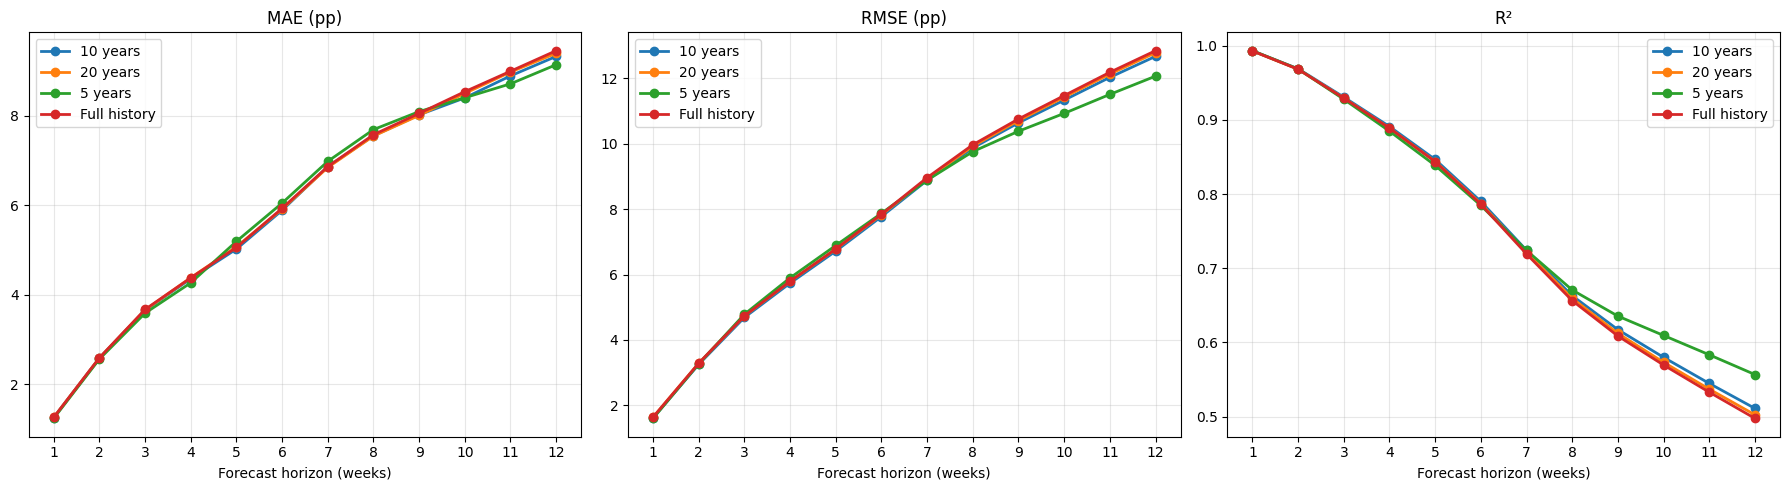

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE (pp)", "RMSE (pp)", "R²"]

for i, metric in enumerate(metrics):

    for history, group in metrics_history.groupby("History"):

        group = group.sort_values("Horizon")

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            linewidth=2,
            label=history
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].set_xticks(range(1, 13))
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

Summary of the averaged performance and running time

In [17]:
summary_history = (
    metrics_history
    .groupby("History")[["MAE (pp)", "RMSE (pp)", "R²"]]
    .mean()
    .reset_index()
    .merge(runtime_history, on="History")
    .sort_values("RMSE (pp)")
)

display(summary_history.round(4))

,History,MAE (pp),RMSE (pp),R²,Runtime (s)
2,5 years,5.9946,7.8212,0.7647,0.7713
0,10 years,5.9858,7.9351,0.7550,1.2424
1,20 years,6.0128,7.9958,0.7514,2.3615
3,Full history,6.0318,8.0234,0.7494,3.3355


We find that a 5-year training history provides better predictive performance over longer forecast horizons than the full history.

Possible explanations include:
- More recent observations may be more representative of current conditions.
- Seasonal patterns may have changed over time.

Therefore I choose  a 5-year training history as the default setting in Streamlit, because it offers better performance over longer time horizons and require less computation time.

## Exogenous variables i SNARIMAX

Existing weather data for NO3 from project 3 

In [18]:
df_weather = pd.read_parquet(
    "../data/weather/NO3_hourly_mean_2024.parquet"
)

display(df_weather.head())

print("Shape:", df_weather.shape)
print("Columns:", df_weather.columns.tolist())

print("Start:", df_weather["time"].min())
print("End:", df_weather["time"].max())

,time,precipitation_mean,n_locations,SATV,temperature_mean
0,2024-01-01 00:00:00+00:00,0.0043,1000,-0.116498,-3.6215
1,2024-01-01 01:00:00+00:00,0.0030,1000,-0.117794,-3.7633
2,2024-01-01 02:00:00+00:00,0.0030,1000,-0.117787,-3.7420
3,2024-01-01 03:00:00+00:00,0.0030,1000,-0.117776,-3.7786
4,2024-01-01 04:00:00+00:00,0.0029,1000,-0.117861,-3.7280


Shape: (8784, 5)
Columns: ['time', 'precipitation_mean', 'n_locations', 'SATV', 'temperature_mean']
Start: 2024-01-01 00:00:00+00:00
End: 2024-12-31 23:00:00+00:00


In project 3 we only have 1 year weather data for NO3. This is unfortuantly not enough for current SNARIMAX model with yearly seasonal patttern m = 52 and five years training history

Fetch daily ERA5-data from 2019 to 2026

In [19]:

download_region_weather_daily(
    region="NO3",
    start_date="2019-01-01",
    end_date="2026-11-15",
    n_locations=90, # Since it took long time with 1000
    batch_size=10
)


Already saved: NO3_2019-01-01_2026-11-15_1_10.parquet
Already saved: NO3_2019-01-01_2026-11-15_11_20.parquet
Already saved: NO3_2019-01-01_2026-11-15_21_30.parquet
Already saved: NO3_2019-01-01_2026-11-15_31_40.parquet
Already saved: NO3_2019-01-01_2026-11-15_41_50.parquet
Already saved: NO3_2019-01-01_2026-11-15_51_60.parquet
Already saved: NO3_2019-01-01_2026-11-15_61_70.parquet
Already saved: NO3_2019-01-01_2026-11-15_71_80.parquet
Already saved: NO3_2019-01-01_2026-11-15_81_90.parquet
Download completed.


In [20]:
folder = Path("../data/weather_daily/NO3")

files = list(folder.glob("*.parquet"))

df_weather_daily = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
)

display(df_weather_daily.head())

print("Number of locations:", df_weather_daily["point_id"].nunique())
print("Shape:", df_weather_daily.shape)

,time,temperature_2m_mean,precipitation_sum,region,point_id
0,2019-01-01,1.0,5.0,NO3,11
1,2019-01-02,-0.0,3.9,NO3,11
2,2019-01-03,2.9,13.5,NO3,11
3,2019-01-04,5.0,17.5,NO3,11
4,2019-01-05,3.2,0.5,NO3,11


Number of locations: 90
Shape: (258840, 5)


In [21]:
display(df_weather_daily.head())

print("Number of locations:", df_weather_daily["point_id"].nunique())
print("Shape:", df_weather_daily.shape)

,time,temperature_2m_mean,precipitation_sum,region,point_id
0,2019-01-01,1.0,5.0,NO3,11
1,2019-01-02,-0.0,3.9,NO3,11
2,2019-01-03,2.9,13.5,NO3,11
3,2019-01-04,5.0,17.5,NO3,11
4,2019-01-05,3.2,0.5,NO3,11


Number of locations: 90
Shape: (258840, 5)


In [22]:
# calculate the average temperature and precipitation across all 90 locations for each day.
    
df_weather_region_daily = (
    df_weather_daily
    .groupby("time")
    .agg(
        temperature_mean=("temperature_2m_mean", "mean"),
        precipitation_mean=("precipitation_sum", "mean"), # aggregated precipitation over geographical locations
        n_locations=("point_id", "nunique")
    )
    .reset_index()
    .sort_values("time")
)

display(df_weather_region_daily.head())

print("Shape:", df_weather_region_daily.shape)
print("Number of locations:", df_weather_region_daily["n_locations"].unique())

# As the reservoir fill data has a weekly time resolution, the weather data must also have this.
df_weather_weekly = (
    df_weather_region_daily
    .set_index("time")
    .resample("W-SUN")
    .agg(
        temperature_mean=("temperature_mean", "mean"),
        precipitation_sum=("precipitation_mean", "sum"), # accumulated precipitation over 7 days
        n_days=("temperature_mean", "count")
    )
    .reset_index()
    .rename(columns={"time": "dato_Id"})
)

# Keep only complete weeks
df_weather_weekly = (
    df_weather_weekly[df_weather_weekly["n_days"] == 7]
    .reset_index(drop=True)
)

display(df_weather_weekly.head())

print("Shape:", df_weather_weekly.shape)

,time,temperature_mean,precipitation_mean,n_locations
0,2019-01-01,1.227778,16.126667,90
1,2019-01-02,0.138889,5.542222,90
2,2019-01-03,3.366667,8.942222,90
3,2019-01-04,5.135556,18.563333,90
4,2019-01-05,4.238889,2.630000,90


Shape: (2876, 4)
Number of locations: [90]


,dato_Id,temperature_mean,precipitation_sum,n_days
0,2019-01-13,0.264762,42.018889,7
1,2019-01-20,-4.208413,39.428889,7
2,2019-01-27,-6.379841,4.073333,7
3,2019-02-03,-5.865079,5.954444,7
4,2019-02-10,-3.464603,12.141111,7


Shape: (410, 4)


In [23]:
# Merge weather data and reservoir levels

df_region_weather = df_region.copy()

# Ensure consistent date format
df_region_weather["dato_Id"] = (
    pd.to_datetime(df_region_weather["dato_Id"])
    .dt.tz_localize(None)
    .dt.normalize()
)

# Merge reservoir filling and weekly weather data
df_region_weather = (
    df_region_weather
    .merge(
        df_weather_weekly[
            ["dato_Id", "temperature_mean", "precipitation_sum"]
        ],
        on="dato_Id",
        how="inner", # we want weeks where we have both reservoir fylling and weather data
        validate="one_to_one"
    )
    .sort_values("dato_Id")
    .reset_index(drop=True)
)

display(df_region_weather.head())

print("Shape:", df_region_weather.shape)
print("Start:", df_region_weather["dato_Id"].min())
print("End:", df_region_weather["dato_Id"].max())

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad,baseline,temperature_mean,precipitation_sum
0,2019-01-13,EL,3,2019,2,0.656155,8.920932,5.853517,0001-01-01T00:00:00,0.668654,-0.012499,0.668654,0.264762,42.018889
1,2019-01-20,EL,3,2019,3,0.623391,8.920932,5.561225,0001-01-01T00:00:00,0.656155,-0.032765,0.656155,-4.208413,39.428889
2,2019-01-27,EL,3,2019,4,0.579069,8.920932,5.165833,0001-01-01T00:00:00,0.623391,-0.044322,0.623391,-6.379841,4.073333
3,2019-02-03,EL,3,2019,5,0.531974,8.920932,4.745702,0001-01-01T00:00:00,0.578997,-0.047023,0.579069,-5.865079,5.954444
4,2019-02-10,EL,3,2019,6,0.487957,8.920932,4.353035,0001-01-01T00:00:00,0.531974,-0.044016,0.531974,-3.464603,12.141111


Shape: (410, 14)
Start: 2019-01-13 00:00:00
End: 2026-11-15 00:00:00


Check for any missing values and missing weeks:

In [24]:
df_region_weather.isna().sum()

dato_Id                     0
omrType                     0
omrnr                       0
iso_aar                     0
iso_uke                     0
fyllingsgrad                0
kapasitet_TWh               0
fylling_TWh                 0
neste_Publiseringsdato      0
fyllingsgrad_forrige_uke    0
endring_fyllingsgrad        0
baseline                    0
temperature_mean            0
precipitation_sum           0
dtype: int64

In [25]:
expected_dates = pd.date_range(
    start=df_region_weather["dato_Id"].min(),
    end=df_region_weather["dato_Id"].max(),
    freq="W-SUN"
)

missing_dates = expected_dates.difference(
    df_region_weather["dato_Id"]
)

print("Missing weeks:", len(missing_dates))
print(missing_dates)

Missing weeks: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='W-SUN')


When we forecast reservoir levels 12 weeks ahead, we do not know the actual temperature and rainfall for those weeks. I calculate the average temperature and rainfall for each calendar week based on the last five years’ available observations.

We can then investigate whether including weather variables yields better results than SNARIMAX without exogenous variables.

In [26]:
from src.forecasting import estimate_future_weather

# For example, when we need to forecast the weather for week 48 in 2026, 
# we use the average for the corresponding weeks in previous years. (week 48 in 2021, 2022, 2023...)

future_weather = estimate_future_weather(
    df=df_region_weather,
    horizon=12,
    history_years=5
)

future_weather.head()

,date,temperature_mean,precipitation_sum
0,2026-11-22,-1.946857,36.513111
1,2026-11-29,-3.187651,21.885111
2,2026-12-06,-3.492095,12.090222
3,2026-12-13,-0.919111,50.171556
4,2026-12-20,-0.987937,37.638000


In [27]:
from src.forecasting import evaluate_exogenous_variables

predictions_exog, metrics_exog, runtime_exog = (
    evaluate_exogenous_variables(
        df=df_region_weather,
        horizon=12,
        val_weeks=52,
        history_weeks=5 * 52,
        origin_step=1,
        snarimax_params=best_params,
        weather_history_years=5
    )
)

Evaluating: Without weather
Evaluating: Temperature
Evaluating: Precipitation
Evaluating: Temperature + Precipitation


I use this period (the last 52 weeks) repeatedly for model selection, it is a validation set, not an independent test set.

In [28]:
summary_exog = (
    metrics_exog
    .groupby("Model")[["MAE (pp)", "RMSE (pp)", "R²"]]
    .mean()
    .reset_index()
    .merge(runtime_exog, on="Model")
    .sort_values("RMSE (pp)")
)

display(summary_exog.round(4))

,Model,MAE (pp),RMSE (pp),R²,Runtime (s)
1,Temperature,5.6114,7.1388,0.8088,1.3259
2,Temperature + Precipitation,6.1616,7.5947,0.7841,1.2971
3,Without weather,5.9946,7.8212,0.7647,0.8409
0,Precipitation,6.2299,8.2173,0.7422,1.2577


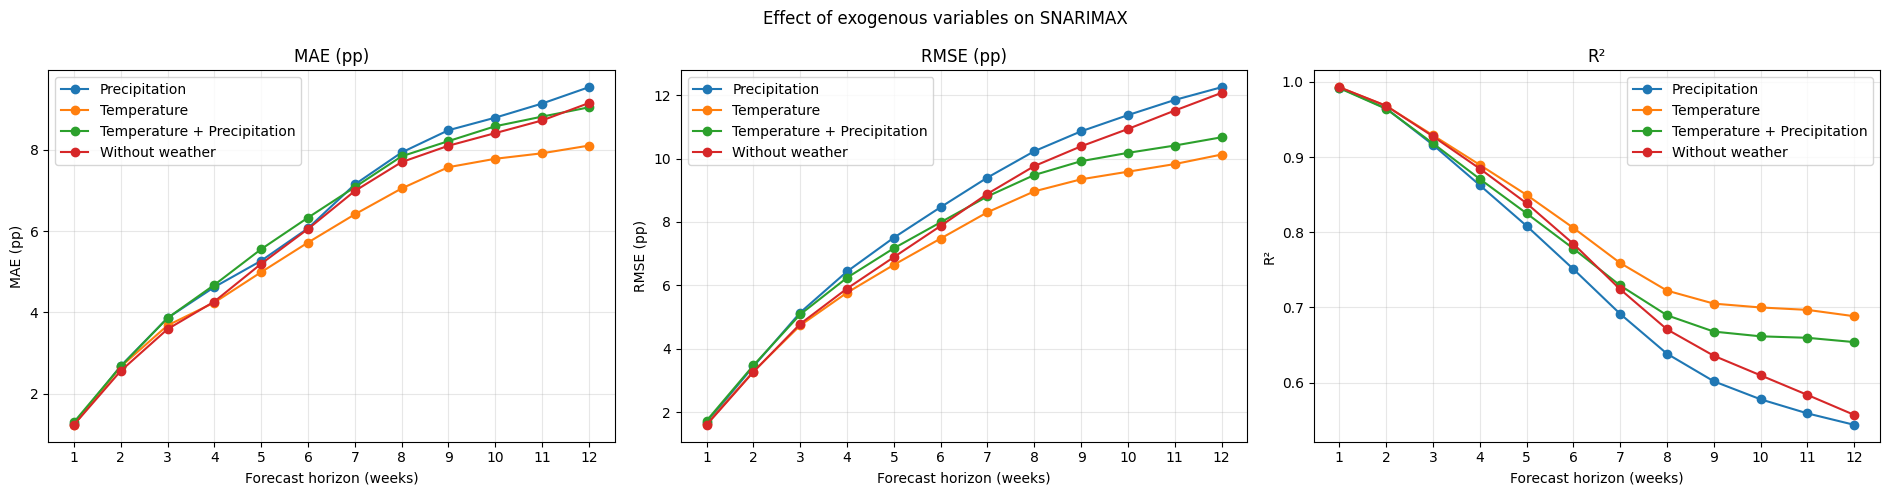

In [29]:

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

metrics = ["MAE (pp)", "RMSE (pp)", "R²"]

for ax, metric in zip(axes, metrics):

    for label, group in metrics_exog.groupby("Model"):

        group = group.sort_values("Horizon")

        ax.plot(
            group["Horizon"],
            group[metric],
            marker="o",
            label=label
        )

    ax.set_title(metric)
    ax.set_xlabel("Forecast horizon (weeks)")
    ax.set_ylabel(metric)
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Effect of exogenous variables on SNARIMAX")
plt.tight_layout()
plt.show()

SNARIMAX, with temperature as the exogenous variable, performs best, particularly over longer forecast horizons.

It is  that temperature has a more stable seasonal pattern than precipitation, and that temperature affects snowmelt and thus the inflow to the reservoirs.

Precipitation, on the other hand, varies considerably from week to week. Historical weekly averages may therefore be less representative of future precipitation.

This does not necessarily mean that precipitation is an unimportant variable, but that the current method for estimating future precipitation may not provide the model with useful information.

Based on these validation results, SNARIMAX with temperature is selected as the preferred model configuration.

## Time resolution

The NVE data is already published on a weekly basis. I therefore compare only two options: weekly and biweekly

In [30]:


predictions_resolution, metrics_resolution, runtime_resolution = (
    evaluate_time_resolution(
        df=df_region_weather,
        val_weeks=52,
        horizon=12,
        history_weeks=5 * 52,
        snarimax_params=best_params
    )
)

Evaluating: Weekly
Evaluating: Biweekly


In [31]:
summary_resolution = (
    metrics_resolution
    .groupby("Resolution")[["MAE (pp)", "RMSE (pp)", "R²"]]
    .mean()
    .reset_index()
    .merge(runtime_resolution, on="Resolution")
    .sort_values("RMSE (pp)")
)

display(summary_resolution.round(4))

,Resolution,MAE (pp),RMSE (pp),R²,Runtime (s)
1,Weekly,5.9241,7.5326,0.7957,0.997
0,Biweekly,6.1523,7.7941,0.7811,0.862


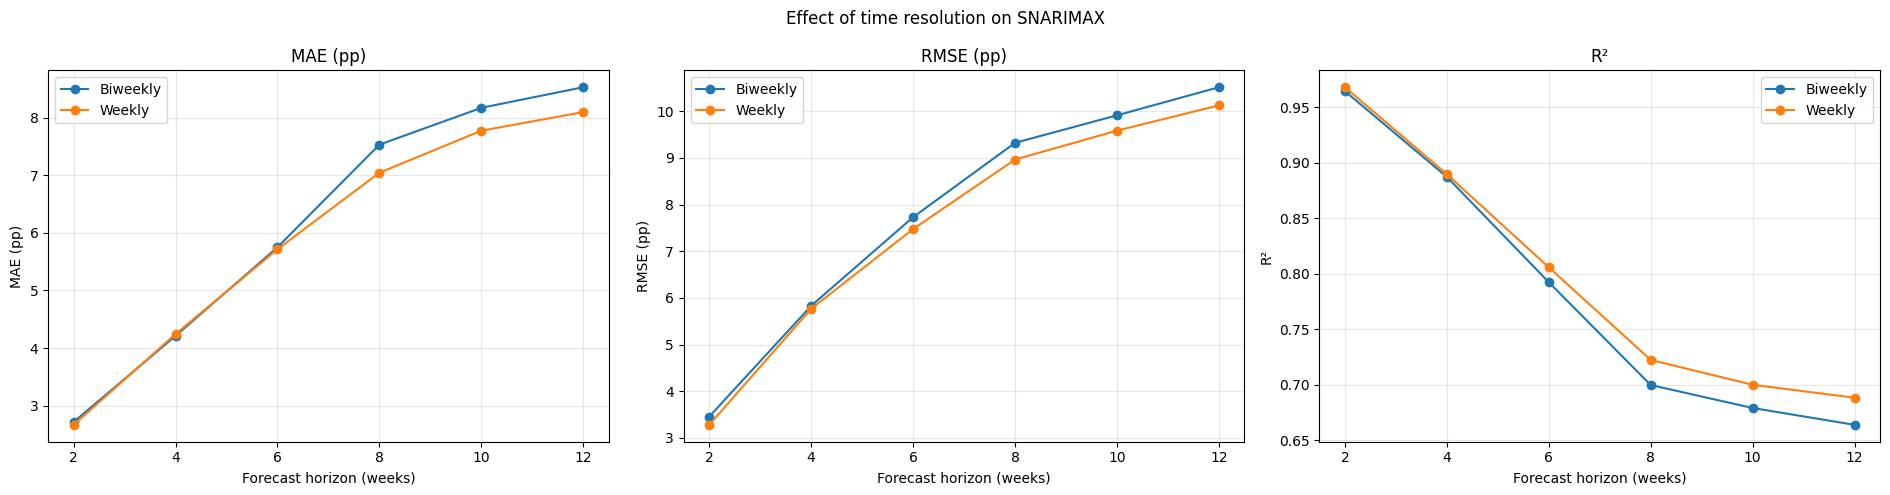

In [32]:

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

metrics = ["MAE (pp)", "RMSE (pp)", "R²"]

for ax, metric in zip(axes, metrics):

    for label, group in metrics_resolution.groupby("Resolution"):

        group = group.sort_values("Horizon")

        ax.plot(
            group["Horizon"],
            group[metric],
            marker="o",
            label=label
        )

    ax.set_title(metric)
    ax.set_xlabel("Forecast horizon (weeks)")
    ax.set_ylabel(metric)
    ax.set_xticks([2, 4, 6, 8, 10, 12])
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Effect of time resolution on SNARIMAX")
plt.tight_layout()
plt.show()

Weekly time resolution performs better than Biweekly time resolution, particularly for longer forecast horizons.

In [33]:
import geopandas as gpd
from pathlib import Path

project_root = Path.cwd().parent

gdf_weather = gpd.read_file(
    project_root / "data" / "weather_regions.geojson"
)

gdf_weather

,region,geometry
0,Nord,"POLYGON ((15.51729 66.55129, 15.45106 66.52397..."
1,Vest,"POLYGON ((9.06206 62.37261, 9.03652 62.36454, ..."
2,Øst,"POLYGON ((10.57616 58.76183, 10.35937 58.77128..."


In [34]:
gdf_weather.drop(columns="geometry")

,region
0,Nord
1,Vest
2,Øst


# Experiment sliding window correlation

Illustration image

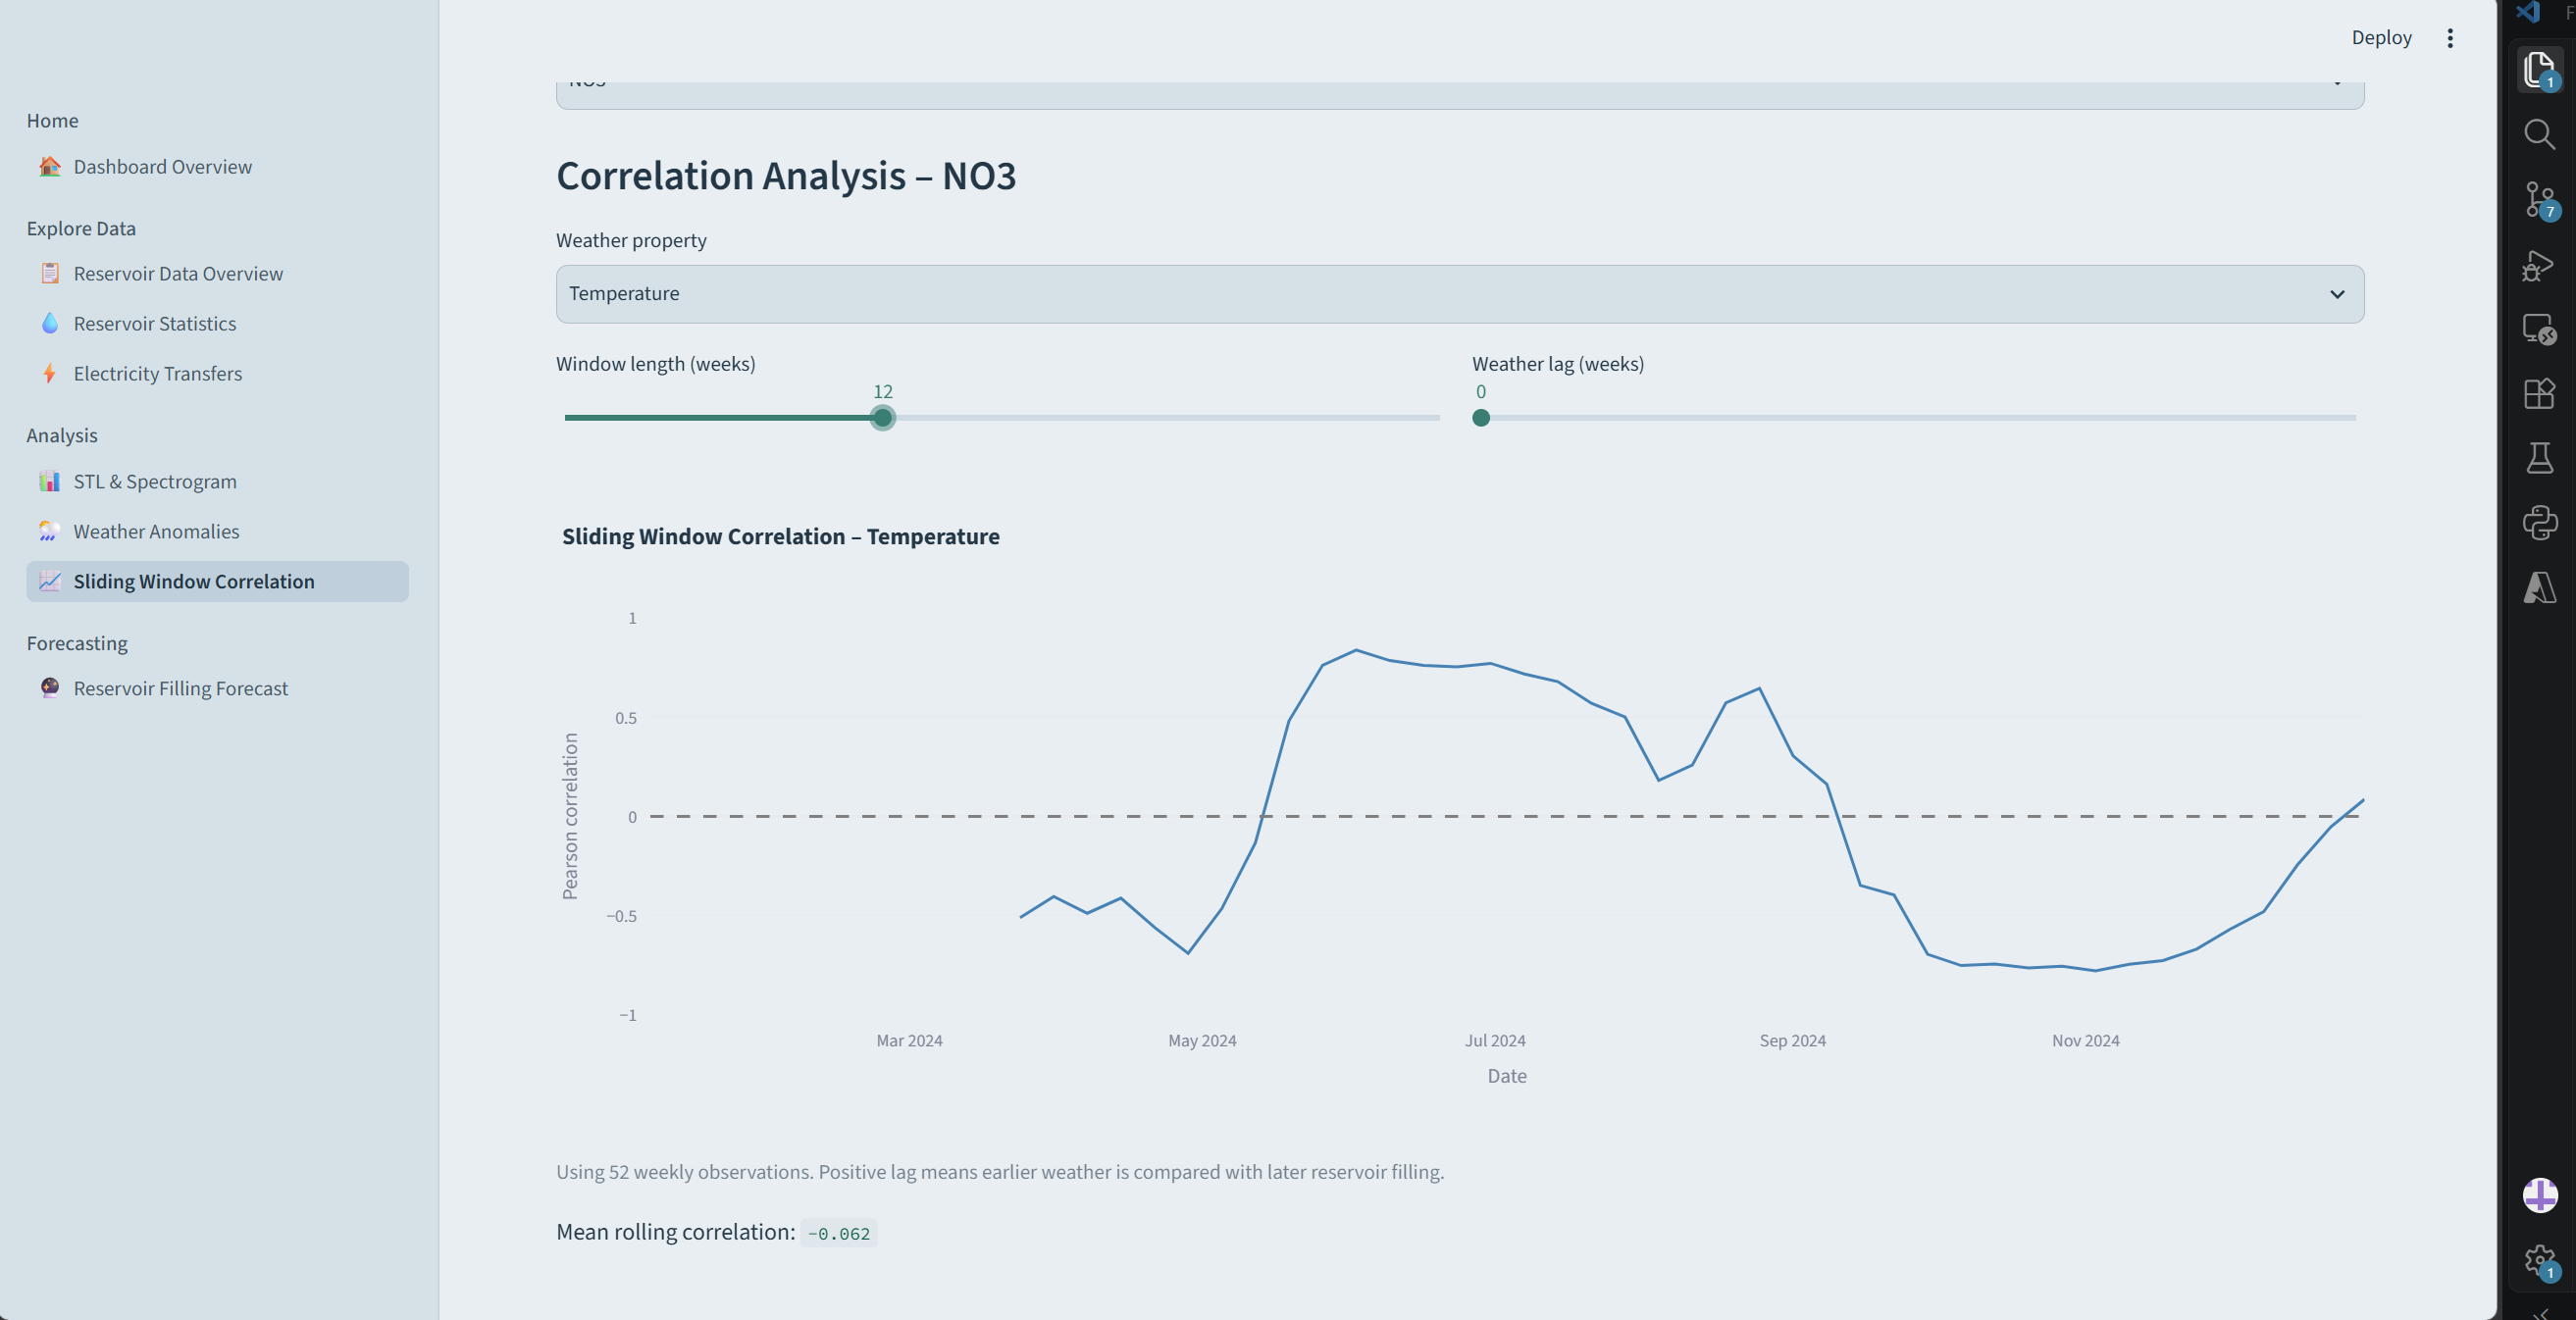



In [35]:
data = [
    {"Experiment": 1, "Weather": "Temperature", "Window": 12, "Lag": 0, "Mean correlation": -0.062},
    {"Experiment": 2, "Weather": "Temperature", "Window": 12, "Lag": 4, "Mean correlation": 0.110},
    {"Experiment": 3, "Weather": "Temperature", "Window": 12, "Lag": 8, "Mean correlation": 0.347},
    {"Experiment": 4, "Weather": "Precipitation", "Window": 12, "Lag": 0, "Mean correlation": 0.282},
    {"Experiment": 5, "Weather": "Precipitation", "Window": 12, "Lag": 4, "Mean correlation": 0.175},
    {"Experiment": 6, "Weather": "Precipitation", "Window": 12, "Lag": 8, "Mean correlation": 0.045},
    {"Experiment": 7, "Weather": "Temperature", "Window": 4, "Lag": 0, "Mean correlation": 0.014},
    {"Experiment": 8, "Weather": "Temperature", "Window": 26, "Lag": 0, "Mean correlation": 0.014},
]

df_experiments = pd.DataFrame(data)
print(df_experiments.to_string(index=False))

 Experiment       Weather  Window  Lag  Mean correlation
          1   Temperature      12    0            -0.062
          2   Temperature      12    4             0.110
          3   Temperature      12    8             0.347
          4 Precipitation      12    0             0.282
          5 Precipitation      12    4             0.175
          6 Precipitation      12    8             0.045
          7   Temperature       4    0             0.014
          8   Temperature      26    0             0.014


Temperature: The mean correlation increases as the lag is increased from 0 to 8 weeks. This may indicate a delayed relationship between temperature and reservoir levels, for example linked to snowmelt.

Precipitation: We observe the opposite pattern. The correlation is strongest with no lag and decreases as the lag increases.

# Norges Bank API

Daily EUR/NOK and USD/NOK exchange rates are retrieved from the Norges Bank API. The EUR/USD exchange rate is calculated by dividing EUR/NOK by USD/NOK.

In [42]:
from src.NB_API import get_eur_usd_data

df_exchange = get_eur_usd_data(
    start_date="2024-11-17",
    end_date="2026-11-17"
)

# Based on date, check which day of week it is
df_exchange["day_of_week"] = df_exchange["date"].dt.day_name()

df_exchange.head(15)

,date,EUR_NOK,USD_NOK,EUR_USD,day_of_week
0,2024-11-18,11.7170,11.1041,1.055196,Monday
1,2024-11-19,11.6595,11.0224,1.057800,Tuesday
2,2024-11-20,11.6440,11.0244,1.056203,Wednesday
3,2024-11-21,11.6200,11.0393,1.052603,Thursday
4,2024-11-22,11.5680,11.1103,1.041196,Friday
5,2024-11-25,11.5865,11.0400,1.049502,Monday
6,2024-11-26,11.6815,11.1020,1.052198,Tuesday
7,2024-11-27,11.6900,11.1006,1.053096,Wednesday
8,2024-11-28,11.6640,11.0643,1.054201,Thursday
9,2024-11-29,11.6805,11.0590,1.056199,Friday


In [37]:
print("First observations:")
print(df_exchange["date"].head())

print("\nData type:", df_exchange["date"].dtype)
print("Timezone:", df_exchange["date"].dt.tz)

print("\nMissing values:")
print(df_exchange.isna().sum())

First observations:
0   2025-11-17
1   2025-11-18
2   2025-11-19
3   2025-11-20
4   2025-11-21
Name: date, dtype: datetime64[ns]

Data type: datetime64[ns]
Timezone: None

Missing values:
date       0
EUR_NOK    0
USD_NOK    0
EUR_USD    0
dtype: int64


In [ ]:
df_nve = get_nve_data()

print("First observations:")
print(df_nve["dato_Id"].head())

print("\nData type:", df_nve["dato_Id"].dtype)
print("Timezone:", df_nve["dato_Id"].dt.tz)

First observations:
0   1995-01-08
1   1995-01-08
2   1995-01-08
3   1995-01-08
4   1995-01-08
Name: dato_Id, dtype: datetime64[ns]

Data type: datetime64[ns]
Timezone: None


In [ ]:
df_weather = pd.read_parquet(
    "../data/weather/NO3_hourly_mean_2024.parquet"
)

print("First observations:")
print(df_weather["time"].head())

print("\nData type:", df_weather["time"].dtype)
print("Timezone:", df_weather["time"].dt.tz)

First observations:
0   2024-01-01 00:00:00+00:00
1   2024-01-01 01:00:00+00:00
2   2024-01-01 02:00:00+00:00
3   2024-01-01 03:00:00+00:00
4   2024-01-01 04:00:00+00:00
Name: time, dtype: datetime64[ns, UTC]

Data type: datetime64[ns, UTC]
Timezone: UTC


The four data sources were investigated to identify differences in temporal resolution and time zone representation: NVE Magasinstatistikk, Norges bank, Open-Meteo, ENTSO-E.

NVE Magasinstatistikk and Norges Bank provide calendar dates without explicit time zone information. These dates are therefore retained as timezone-naive values rather than assigning an arbitrary time zone.

The Open-Meteo hourly observations contain UTC timestamps. For ENTSO-E, the requested time period is defined in Europe/Oslo, while the retrieved timestamps are converted to UTC during preprocessing (see ``src/ENTSOE_API.py``)

```
# Define the period in norwegian local time
start = pd.Timestamp(start_date, tz="Europe/Oslo")
end = pd.Timestamp(end_date, tz="Europe/Oslo")

# Convert the timestamps into UTC
connection_df.index = connection_df.index.tz_convert("UTC")
```

When combining hourly observations with daily or weekly calendar-based data, the timestamps should be converted to the relevant local time zone before aggregation. Furthermore, temporal resolution and period boundaries must be aligned before merging datasets. Norges Bank observations are only available on business days, while reservoir observations are reported weekly.

It is therefore important to distinguish between time zone conversion, temporal aggregation and calendar-date alignment.
